# APA - Lista de Problemas 1: Problema Individual 2

## "Se me va el dinero" — Análisis de Salud Financiera

In [1]:
# Descomentar para actualizar librerias
# Si se actualiza alguna libreria hay que reiniciar el notebook
# !pip install pandas --upgrade  --quiet
# !pip install numpy --upgrade  --quiet
# !pip install scipy --upgrade  --quiet
# !pip install statsmodels --upgrade  --quiet
# !pip install scikit-learn --upgrade  --quiet
!pip install missingno --upgrade  --quiet
!pip install apafib --upgrade --quiet

In [2]:
from IPython.core.interactiveshell import InteractiveShell
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split,  KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from yellowbrick.regressor import residuals_plot, prediction_error
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
InteractiveShell.ast_node_interactivity = "all"

from time import time
from datetime import timedelta
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pandas.plotting import scatter_matrix
init_time = time()

In [3]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.precision', 3)

## APARTADO A

### CARGA DE DATOS Y VISUALIZACIÓN
Para empezar a resolver el ejercicio, cargamos el conjunto de datos de `personal_spending` de `apafib`.

La base de estos estudios son encuestas que recopilan los diferentes factores que intervienen en la salud financiera. Estamos interesados en saber qué variables tienen alguna influencia y cuanta sobre su valor.

In [4]:
from apafib import load_personal_spending
personalSpending = load_personal_spending()
personalSpending.head()

,age,gender,occupation,city,monthly_income,income_source,savings_rate,debt,housing_expense,food_expense,transport_expense,entertainment_expense,shopping_expense,healthcare_expense,credit_card_usage,investment,emergency_fund,financial_stress,financial_health_score,vacation_last_year,number_of_monthly_take_away,car_ownership,education_level,marital_status,children,home_ownership,political_affiliation,monthly_mobile_usage_minutes,financial_fees
0,37,Male,Unemployed,Suburban,1996.729,Salary,0.025,15837.329,643.880,258.756,144.657,108.919,83.920,147.937,Medium,No,Yes,Medium,29.748,False,1,False,High School,Single,0,False,Democrat,501.129,26.852
1,56,Female,Employee,Suburban,2272.838,Freelance,0.279,3864.472,837.442,191.167,160.847,157.713,184.966,49.048,Medium,Yes,Yes,Medium,75.084,False,0,True,High School,Married,2,False,Democrat,494.006,37.327
2,50,Male,Unemployed,Suburban,4462.068,Salary,0.299,10015.828,1480.339,461.263,303.980,139.675,282.667,298.499,Medium,No,No,Medium,28.500,False,2,False,Bachelor,Single,0,False,Republican,533.844,19.522
3,20,Female,Student,Urban,1090.827,Salary,0.169,1636.841,389.457,153.602,92.880,40.578,64.074,45.550,Medium,Yes,No,Low,27.475,False,0,False,Dropout,Single,0,False,Democrat,533.490,20.000
4,48,Female,Employee,Rural,1690.182,Multiple,0.125,1182.183,620.388,158.246,110.023,188.253,148.276,58.842,Low,Yes,No,Medium,28.920,False,0,False,High School,Single,0,False,Democrat,509.619,26.797


In [5]:
personalSpending.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,3500.0,NaN,NaN,NaN,43.596,13.182,18.0,33.0,45.0,55.0,64.0
gender,3500,2,Female,1854,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,3500,5,Employee,1562,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,3500,3,Urban,1769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_income,3500.0,NaN,NaN,NaN,2711.481,1388.124,437.89,1716.534,2411.643,3369.777,10988.486
income_source,3500,4,Salary,2081,NaN,NaN,NaN,NaN,NaN,NaN,NaN
savings_rate,3500.0,NaN,NaN,NaN,0.202,0.098,0.0,0.134,0.2,0.271,0.575
debt,3500.0,NaN,NaN,NaN,5017.279,6416.069,125.919,1528.91,3068.286,5998.933,93546.385
housing_expense,3500.0,NaN,NaN,NaN,881.202,470.061,117.242,548.297,772.883,1100.941,3947.394
food_expense,3500.0,NaN,NaN,NaN,312.862,174.603,50.041,191.013,272.489,390.894,1639.516


Al observar los valores de la tabla se puede ver que todas las variables tienen 3500 registros (no nulos), por lo que el conjunto de datos está completo y no tiene valores perdidos. También podemos ver que hay una gran diferencia de magnitudes entre las variables (p.ej. `age` va de 18 a 64 mientras que `monthly_income` llega a 10988), lo que significa que deberemos estandarizar más adelante para poder ajustar a modelos de regresión y hacer el PCA.

Podemos hacer una comprobación para asegurarnos de que no hay variables perdidas ejecutando:

In [6]:
personalSpending.isna().sum()

age                             0
gender                          0
occupation                      0
city                            0
monthly_income                  0
income_source                   0
savings_rate                    0
debt                            0
housing_expense                 0
food_expense                    0
transport_expense               0
entertainment_expense           0
shopping_expense                0
healthcare_expense              0
credit_card_usage               0
investment                      0
emergency_fund                  0
financial_stress                0
financial_health_score          0
vacation_last_year              0
number_of_monthly_take_away     0
car_ownership                   0
education_level                 0
marital_status                  0
children                        0
home_ownership                  0
political_affiliation           0
monthly_mobile_usage_minutes    0
financial_fees                  0
dtype: int64

O de forma más gráfica:

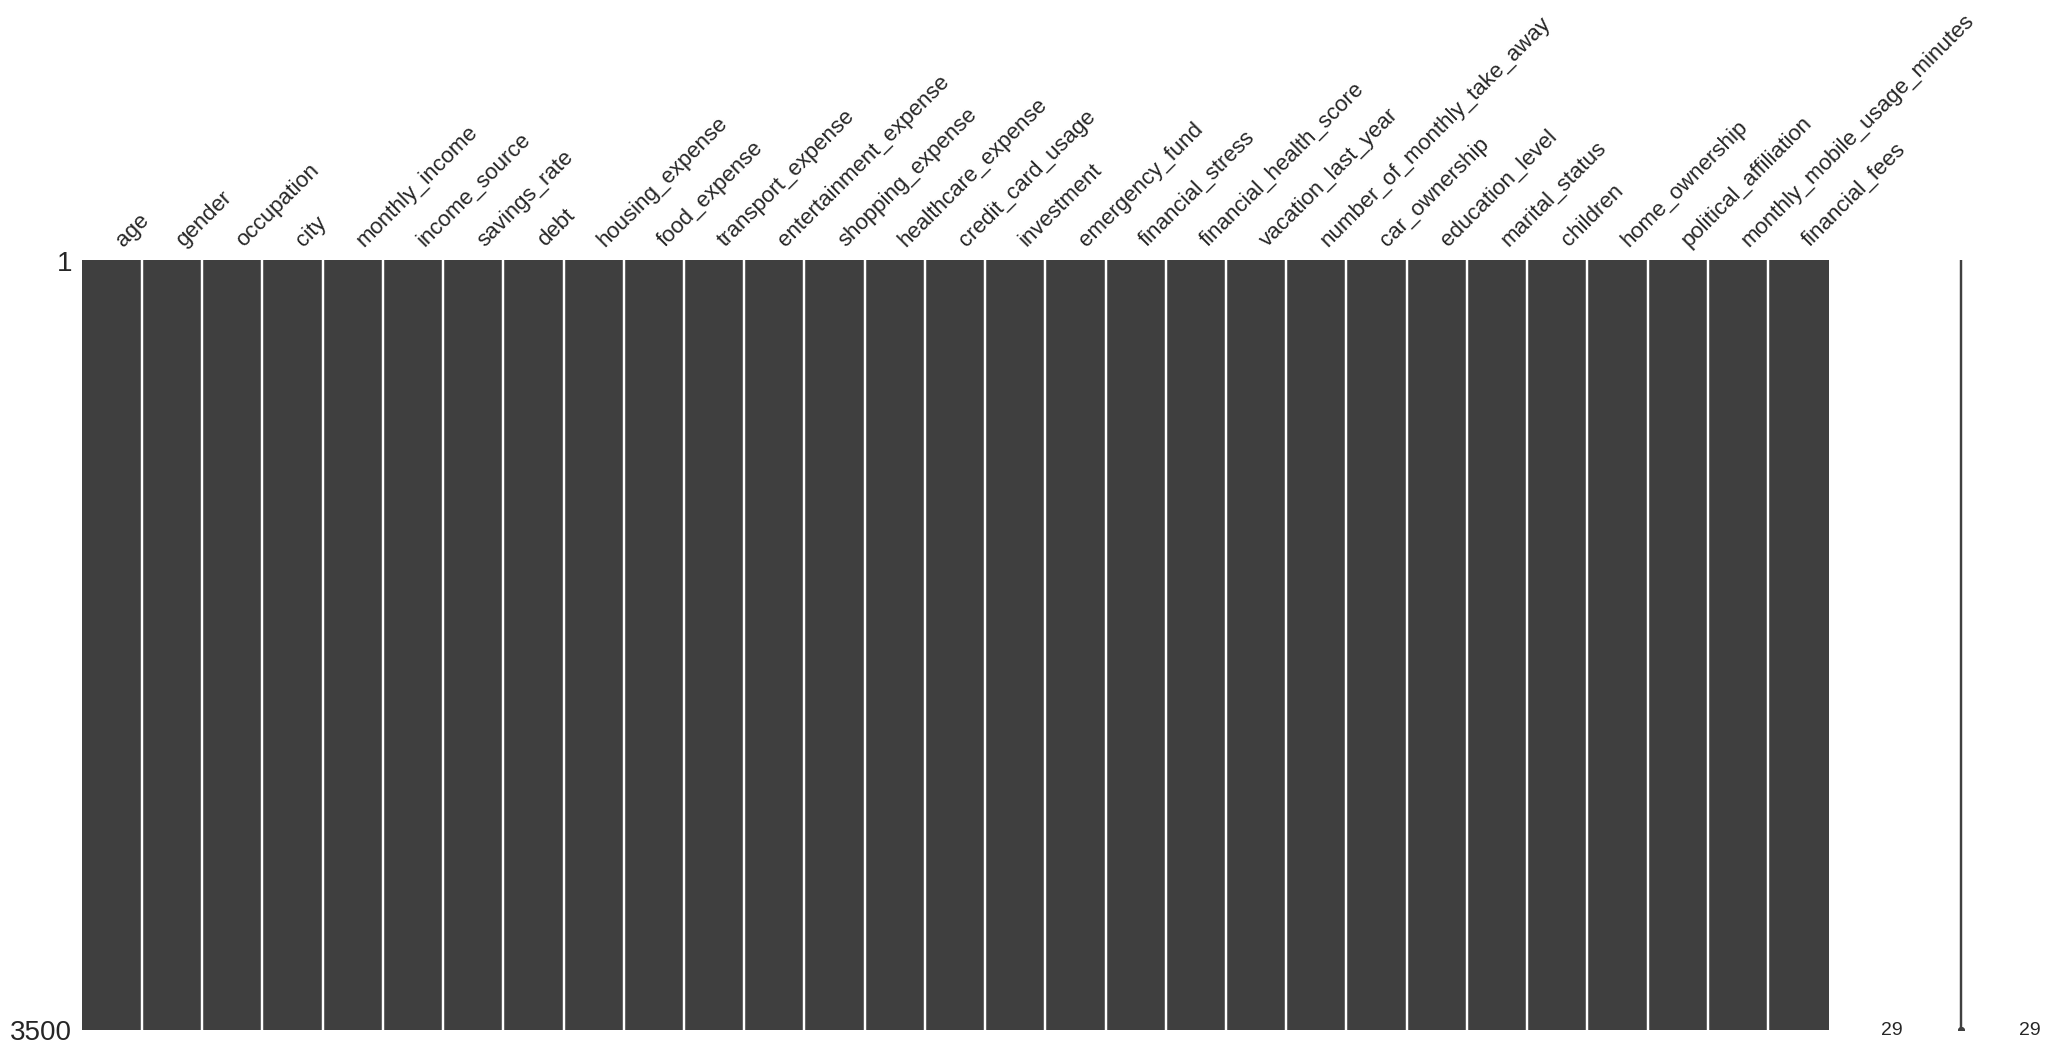

In [7]:
import missingno as msno
msno.matrix(personalSpending);

### División entrenamiento y test
Dividimos el conjunto de datos en entrenamiento y test (80% y 20% respectivamente)

In [8]:
personal_train, personal_test = train_test_split(personalSpending, test_size=0.2, random_state=0)

Generando un heatmap podemos ver la relación entre las diferentes variables para obtener su correlación:

<Figure size 1400x1000 with 0 Axes>

<Axes: >

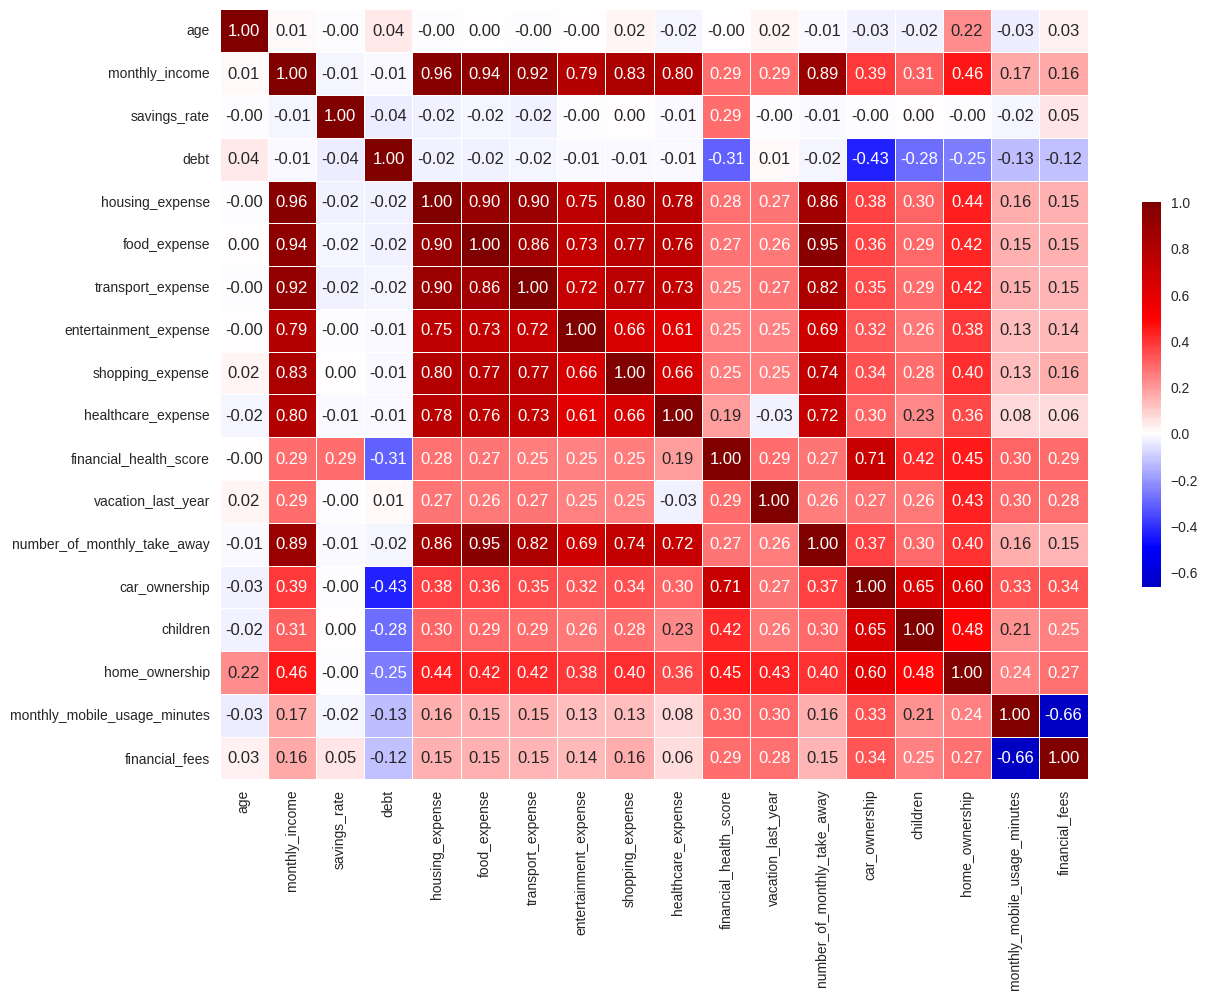

In [9]:
plt.figure(figsize=(14, 10))
corr_matrix = personal_train.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='seismic', center=0, fmt=".2f",
            linewidths=.5, cbar_kws={"shrink": .5})
plt.show()

Al estudiar los resultados podemos ver que hay fuertes relaciones entre variables.

Podemos ver que hay correlaciones con la variable objetivo (`financial_health_score`). Por ejemplo, el tener coche (`car_ownership`) muestra una fuerte correlación lineal positiva (0.71) con la salud financiera, seguida de tener vivienda (`home_ownership`) que tiene 0.45. De forma opuesta, las deudas (`debt`) tienen el mayor impacto negativo (-0.31) con diferencia.

También hay correlaciones entre otras variables. Por ejemplo, existe una correlación muy alta (superior a 0.90) entre los ingresos (`monthly_income`) y los gastos básicos (`housing_expense`, `food_expense`, `transport_expense`).

Esto último, significa que es muy probable que se puedan juntar y/o eliminar variables redundantes. Por el momento esto no se hará, ya que en caso de estar en lo cierto, lo hará la regresión LASSO más adelante.

Otra cosa que podemos hacer es generar un histograma para ver la distribución de cada variable.

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'monthly_income'}>,
        <Axes: title={'center': 'savings_rate'}>,
        <Axes: title={'center': 'debt'}>],
       [<Axes: title={'center': 'housing_expense'}>,
        <Axes: title={'center': 'food_expense'}>,
        <Axes: title={'center': 'transport_expense'}>,
        <Axes: title={'center': 'entertainment_expense'}>],
       [<Axes: title={'center': 'shopping_expense'}>,
        <Axes: title={'center': 'healthcare_expense'}>,
        <Axes: title={'center': 'financial_health_score'}>,
        <Axes: title={'center': 'number_of_monthly_take_away'}>],
       [<Axes: title={'center': 'children'}>,
        <Axes: title={'center': 'monthly_mobile_usage_minutes'}>,
        <Axes: title={'center': 'financial_fees'}>, <Axes: >]],
      dtype=object)

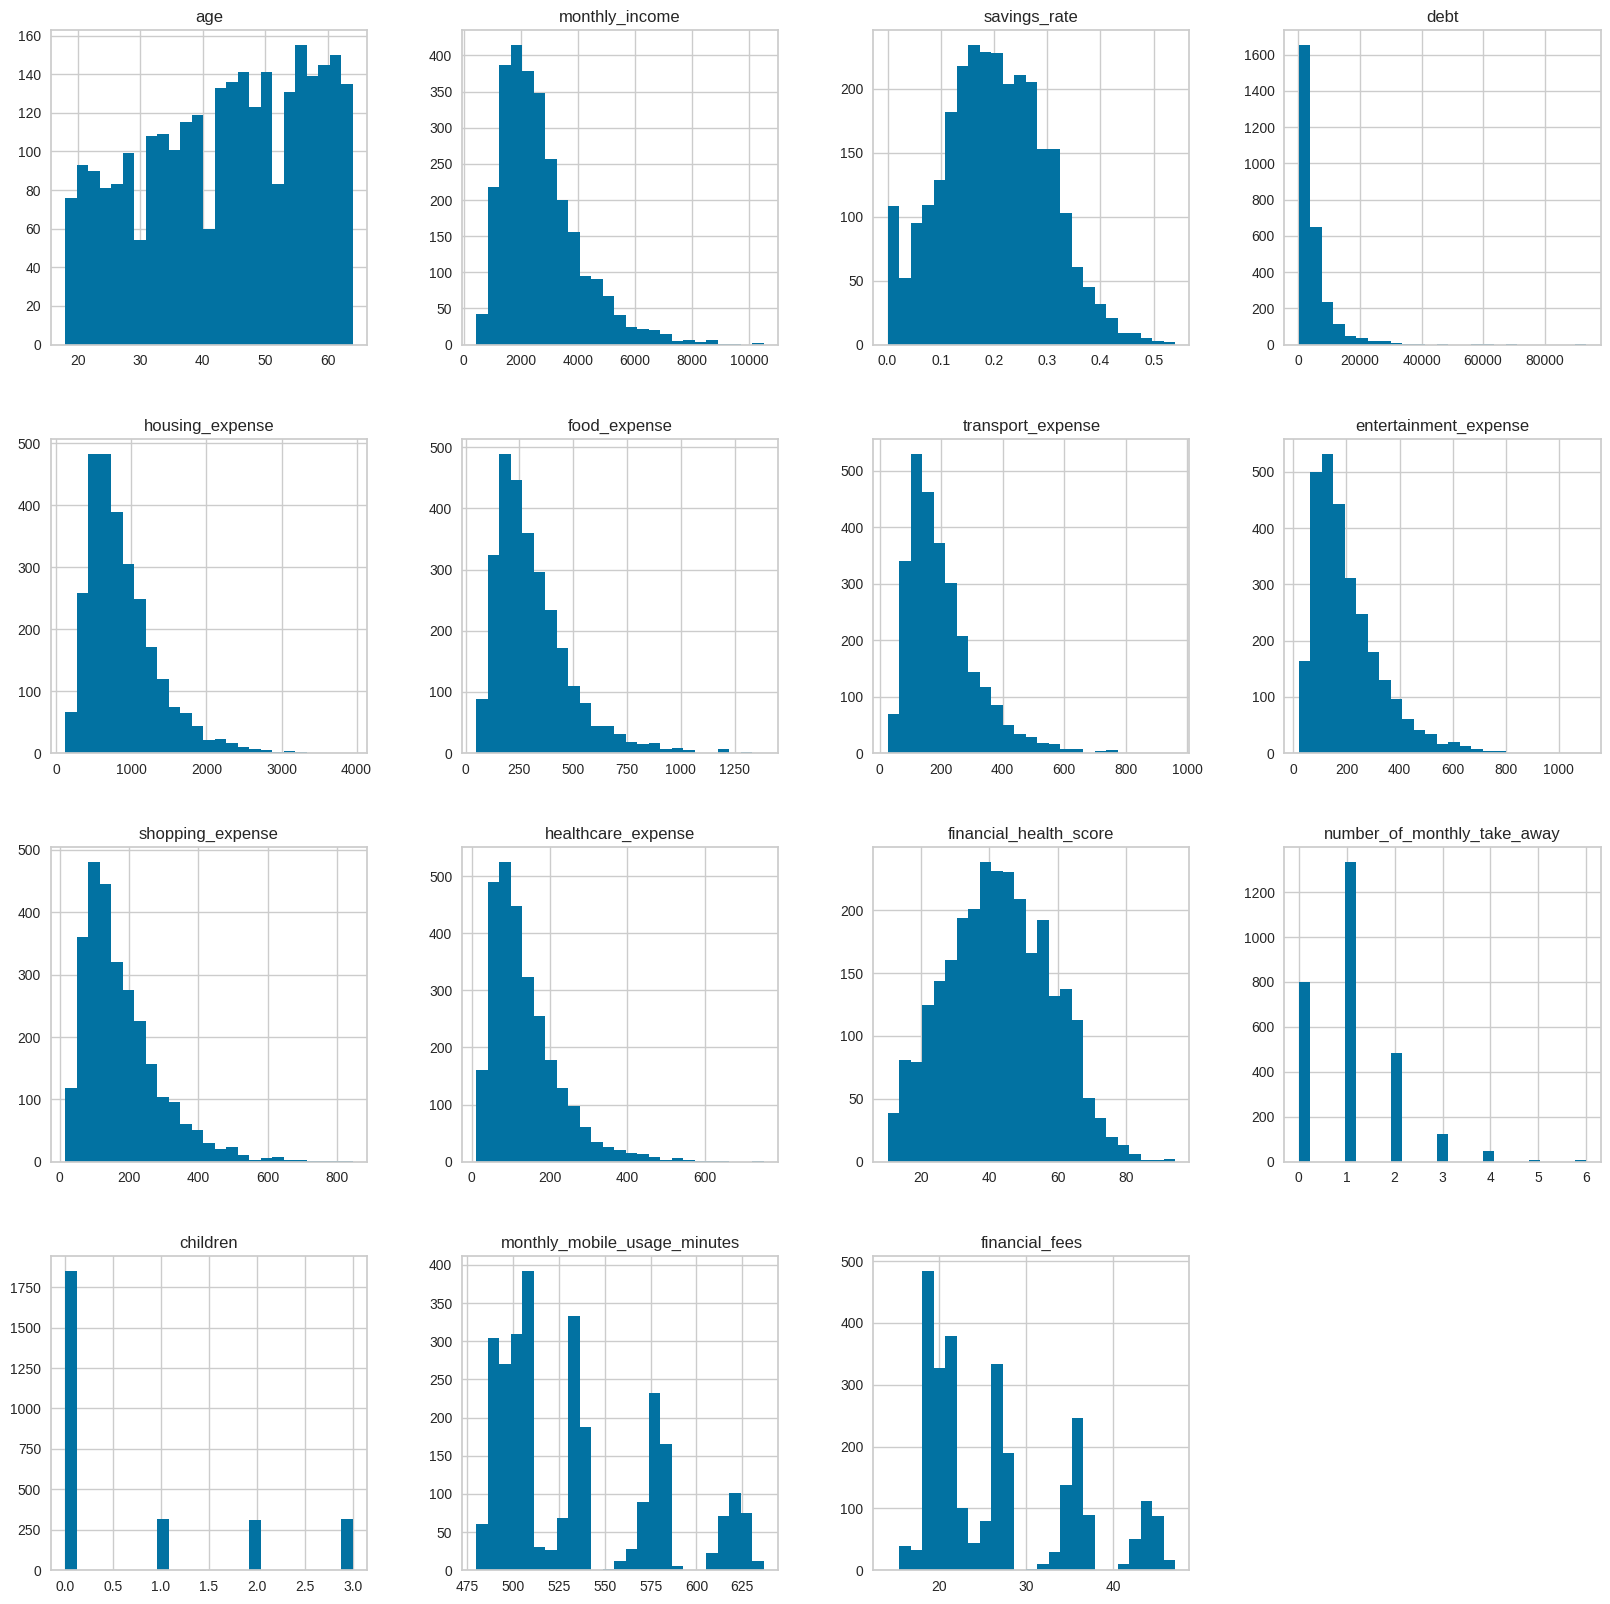

In [10]:
personal_train.hist(bins=25, figsize=(20, 20));
plt.show()

Al observar los histogramas, podemos destacar que las variables económicas (ingresos, deudas y gastos) presentan un fuerte sesgo positivo, concentrando a la mayoría en valores moderados con una larga cola hacia la derecha. Otras variables, como los hijos, muestran patrones discretos o con varios picos. Sin embargo, lo más importante es que la variable objetivo (`financial_health_score`) tiene una distribución simétrica y acampanada, presentando una forma casi gaussiana.

También podemos comprobar la relación de variables categóricas con la variable objetivo (salud financiera) con gráficas de tipo violinplot:

<Axes: xlabel='financial_stress', ylabel='financial_health_score'>

Text(0.5, 1.0, 'financial_stress')

<Axes: xlabel='education_level', ylabel='financial_health_score'>

Text(0.5, 1.0, 'education_level')

<Axes: xlabel='credit_card_usage', ylabel='financial_health_score'>

Text(0.5, 1.0, 'credit_card_usage')

... (18 outputs left out)

<Axes: xlabel='home_ownership', ylabel='financial_health_score'>

Text(0.5, 1.0, 'home_ownership')

<Axes: xlabel='political_affiliation', ylabel='financial_health_score'>

Text(0.5, 1.0, 'political_affiliation')

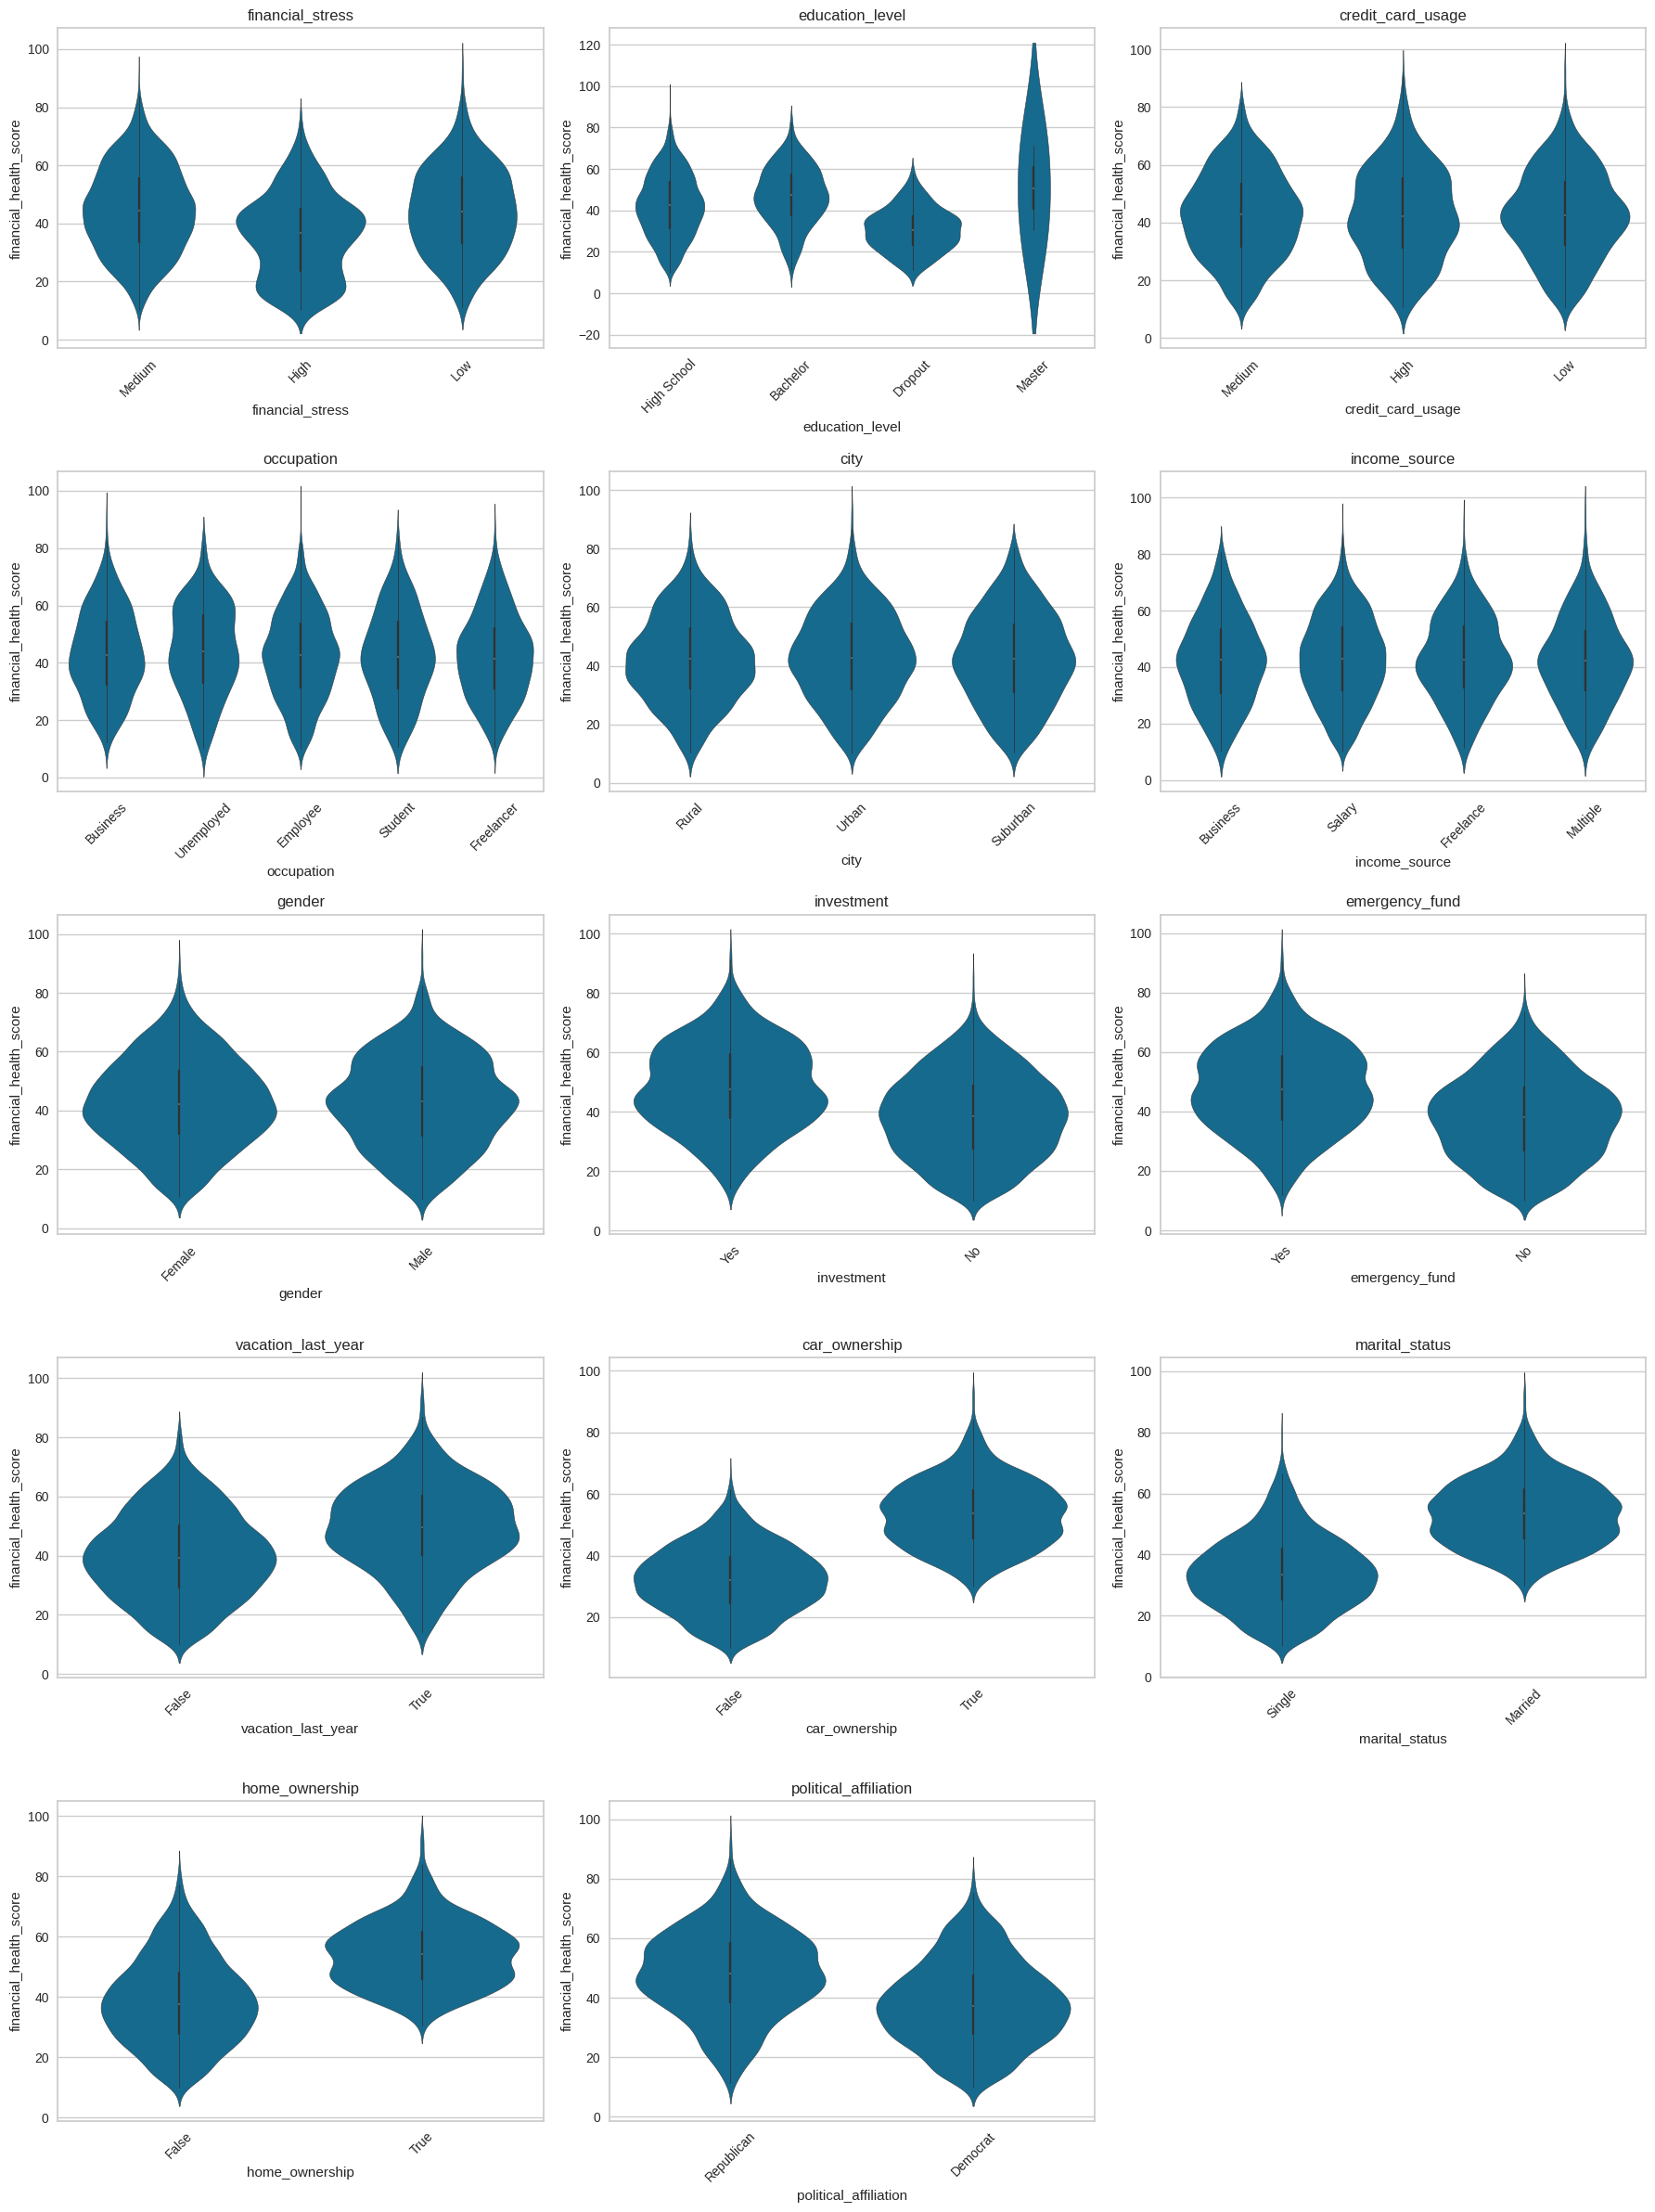

In [11]:
# Variables categóricas
variables = [
    "financial_stress",
    "education_level",
    "credit_card_usage",
    "occupation",
    "city",
    "income_source",
    "gender",
    "investment",
    "emergency_fund",
    "vacation_last_year",
    "car_ownership",
    "marital_status",
    "home_ownership",
    "political_affiliation"
]

# Creamos una matriz para poner todas las gráficas en la misma imagen
fig, axes = plt.subplots(5, 3, figsize=(18, 24))
axes = axes.flatten()

for i, variable in enumerate(variables):
    sns.violinplot(
        data=personal_train,
        x=variable,
        y="financial_health_score",
        ax=axes[i]
    )

    axes[i].set_title(variable)
    axes[i].tick_params(axis="x", rotation=45)

# Eliminar subplot vacío
for j in range(len(variables), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Al observar los gráficos de violín, es evidente que existen factores sociodemográficos y económicos que desplazan la distribución de la salud financiera hacia puntuaciones más altas, como puede ser el tener coche, casa propia, inversiones, un fondo de emergencia, haber ido de vacaciones, estar casado o poseer estudios superiores como un Máster. Por el contrario, el abandono escolar (Dropout) o un alto estrés financiero concentran la mayor parte de los datos en la zona baja de las puntuaciones. Finalmente, variables como el género o la afiliación política muestran formas muy similares en todas sus categorías, lo que nos puede indicar que no tienen un impacto real en la variable objetivo y probablemente acaben siendo descartadas en el futuro.

### Transformación de Variables (Preprocesamiento)
A continuación, transformamos las variables una a una según su tipología para que los algoritmos puedan procesarlas correctamente:

**Variables ordinales (tienen un orden jerárquico o se puede entender que lo tienen):**
- financial_stress (Low, Medium, High)
- education_level (Dropout, High School, Bachelor, Master)
- credit_card_usage (Low, Medium, High)

Al tener orden lógico, podemos asignar valores secuenciales a estas variables para preservar su magnitud (0, 1, 2, 3)

**Variables Binarias:**
- gender (Male, Female)
- investment (Yes, No)
- emergency_fund (Yes, No)
- vacation_last_year (TRUE, FALSE)
- car_ownership (TRUE, FALSE)
- marital_status (Married, Single)
- home_ownership (TRUE, FALSE)
- political_affiliation (Democrat, Republican)

Al tener solo 2 valores se pueden convertir en valores binarios (0 o 1).

**Variables Nominales (Múltiples opciones sin orden):**
- occupation (Unemployed, Employee, Student, Business, Freelancer)
- city (Rural, Suburban, Urban)
- income_source (Business, Salary, Freelance, Multiple)

No podemos asignar números secuenciales porque los valores de las variables no siguen ningún orden. Aplicaremos One-Hot Encoding (get_dummies), eliminando la primera columna (drop_first=True).

In [12]:
# transformar variables ordinales
stress_map = {'Low': 0, 'Medium': 1, 'High': 2}
edu_map = {'Dropout': 0, 'High School': 1, 'Bachelor': 2, 'Master': 3}
cc_map = {'Low': 0, 'Medium': 1, 'High': 2}


for df in [personal_train, personal_test]:
    df['financial_stress'] = df['financial_stress'].map(stress_map)
    df['education_level'] = df['education_level'].map(edu_map)
    df['credit_card_usage'] = df['credit_card_usage'].map(cc_map)

# variables binarias y nominales (One-Hot Encoding)
cat_cols = personal_train.select_dtypes(include=['object', 'bool']).columns.tolist()

# Transformamos en train
dummies_train = pd.get_dummies(personal_train[cat_cols], drop_first=True, dtype=int)
personal_train = pd.concat([personal_train.drop(columns=cat_cols), dummies_train], axis=1)

# Transformamos en test
dummies_test = pd.get_dummies(personal_test[cat_cols], drop_first=True, dtype=int)
personal_test = pd.concat([personal_test.drop(columns=cat_cols), dummies_test], axis=1)

# Alinear columnas para evitar problemas si faltan categorías en test
personal_train, personal_test = personal_train.align(personal_test, join='left', axis=1, fill_value=0)
personal_train.head()

,age,monthly_income,savings_rate,debt,housing_expense,food_expense,transport_expense,entertainment_expense,shopping_expense,healthcare_expense,credit_card_usage,financial_stress,financial_health_score,number_of_monthly_take_away,education_level,children,monthly_mobile_usage_minutes,financial_fees,vacation_last_year,car_ownership,home_ownership,gender_Male,occupation_Employee,occupation_Freelancer,occupation_Student,occupation_Unemployed,city_Suburban,city_Urban,income_source_Freelance,income_source_Multiple,income_source_Salary,investment_Yes,emergency_fund_Yes,marital_status_Single,political_affiliation_Republican
1236,46,2620.839,0.289,9838.544,918.369,365.662,184.858,180.502,226.747,200.555,1,1,49.319,1,1,0,539.184,18.389,False,False,False,0,0,0,0,0,0,0,0,0,0,1,1,1,1
1929,44,4580.622,0.111,6783.338,1205.724,651.661,441.231,207.369,372.090,242.273,2,1,35.374,3,2,0,500.164,27.188,False,False,False,0,0,0,0,1,0,0,0,0,1,1,0,1,1
3297,30,3795.942,0.321,6152.648,1397.575,314.068,228.440,130.705,280.332,107.690,1,1,39.757,1,1,0,574.152,19.107,True,False,False,0,1,0,0,0,0,1,0,0,1,0,1,1,1
1768,25,1496.259,0.066,697.158,457.728,200.559,138.375,142.098,83.673,92.868,1,2,12.159,1,1,0,498.093,25.154,False,False,False,0,0,0,0,0,0,1,0,0,1,0,0,1,0
890,51,1020.202,0.306,1093.104,376.545,101.884,51.466,61.205,55.260,48.149,1,2,37.109,0,1,0,536.404,21.686,False,False,False,1,0,0,1,0,1,0,0,0,0,1,1,1,0


Los valores ahora han sido transformados correctamente. Por ejemplo 'gender' se ha transformado a 'gender_Male' (guarda 0 o 1), o 'financial_stress' que ahora guarda valores númericos (1-3).

### Estandarización

Separamos X e Y para no alterar la métrica de la variable a predecir.

Estandarizamos X (media 0, desviación 1) para que PCA y LASSO no den más peso a las variables solo por tener valores más grandes (en Y no se hace porque es la variable objetivo).

In [13]:
# Separamos x e y (y = variable objetivo)
y_train = personal_train['financial_health_score']
X_train = personal_train.drop(columns=['financial_health_score'])

y_test = personal_test['financial_health_score']
X_test = personal_test.drop(columns=['financial_health_score'])

scaler = StandardScaler()

# Ajustamos y transformamos X_train
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)

# Transformamos X_test
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)
X_train_scaled.head()

,age,monthly_income,savings_rate,debt,housing_expense,food_expense,transport_expense,entertainment_expense,shopping_expense,healthcare_expense,credit_card_usage,financial_stress,number_of_monthly_take_away,education_level,children,monthly_mobile_usage_minutes,financial_fees,vacation_last_year,car_ownership,home_ownership,gender_Male,occupation_Employee,occupation_Freelancer,occupation_Student,occupation_Unemployed,city_Suburban,city_Urban,income_source_Freelance,income_source_Multiple,income_source_Salary,investment_Yes,emergency_fund_Yes,marital_status_Single,political_affiliation_Republican
0,0.191,-0.061,0.901,0.803,0.082,0.302,-0.158,-0.169,0.456,0.707,0.186,0.125,-0.053,-0.265,-0.64,0.124,-1.001,-0.630,-0.979,-0.586,-0.942,-0.912,-0.427,-0.422,-0.317,-0.647,-1.021,-0.425,-0.336,-1.197,1.133,1.022,0.893,1.052
1,0.038,1.354,-0.909,0.301,0.690,1.938,2.107,0.043,1.781,1.173,1.632,0.125,2.067,1.981,-0.64,-0.810,0.061,-0.630,-0.979,-0.586,-0.942,-0.912,-0.427,-0.422,3.159,-0.647,-1.021,-0.425,-0.336,0.835,1.133,-0.979,0.893,1.052
2,-1.029,0.788,1.224,0.198,1.096,0.007,0.227,-0.561,0.945,-0.330,0.186,0.125,-0.053,-0.265,-0.64,0.962,-0.914,1.588,-0.979,-0.586,-0.942,1.097,-0.427,-0.422,-0.317,-0.647,0.979,-0.425,-0.336,0.835,-0.883,1.022,0.893,1.052
3,-1.410,-0.873,-1.375,-0.699,-0.893,-0.642,-0.569,-0.471,-0.848,-0.495,0.186,1.541,-0.053,-0.265,-0.64,-0.859,-0.185,-0.630,-0.979,-0.586,-0.942,-0.912,-0.427,-0.422,-0.317,-0.647,0.979,-0.425,-0.336,0.835,-0.883,-0.979,0.893,-0.951
4,0.572,-1.216,1.075,-0.634,-1.065,-1.206,-1.337,-1.109,-1.107,-0.995,0.186,1.541,-1.113,-0.265,-0.64,0.058,-0.603,-0.630,-0.979,-0.586,1.061,-0.912,-0.427,2.371,-0.317,1.546,-1.021,-0.425,-0.336,-1.197,1.133,1.022,0.893,-0.951


In [14]:
X_train_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
age,2800.0,1.624e-16,1.0,-1.944,-0.800,0.114,0.877,1.563
monthly_income,2800.0,2.030e-17,1.0,-1.637,-0.726,-0.214,0.476,5.648
savings_rate,2800.0,-1.059e-16,1.0,-2.042,-0.688,-0.016,0.700,3.458
debt,2800.0,-9.009e-17,1.0,-0.793,-0.561,-0.307,0.167,14.562
housing_expense,2800.0,1.776e-17,1.0,-1.614,-0.711,-0.229,0.467,6.494
food_expense,2800.0,-1.269e-17,1.0,-1.503,-0.701,-0.236,0.458,6.138
transport_expense,2800.0,1.675e-16,1.0,-1.561,-0.709,-0.244,0.447,6.689
entertainment_expense,2800.0,-2.829e-16,1.0,-1.432,-0.727,-0.256,0.469,7.112
shopping_expense,2800.0,9.262e-17,1.0,-1.467,-0.722,-0.260,0.484,6.095
healthcare_expense,2800.0,-3.172e-17,1.0,-1.401,-0.714,-0.243,0.450,6.847


Con el describe podemos ver que el escalado es correcto y que todas las variables poseen ahora el mismo rango. Además, esto es visible porque la media (mean) es cero (o prácticamente 0) y la desviación estándar (std) es exactamente 1.0 en todas las características.

## APARTADO B - PCA

Aplicamos PCA sobre los datos estandarizados para extraer los componentes principales y representamos la varianza explicada mediante un Scree plot.

Varianza explicada: [0.26336386 0.07769145 0.05133398 0.04974319 0.0451126  0.04400254
 0.03827561 0.03534746 0.03427735 0.03381949 0.03290158 0.03085695
 0.02982337 0.02900824 0.02855758 0.02774788 0.0270776  0.01966226
 0.0137345  0.01137112 0.0109866  0.0096457  0.0093989  0.00886445
 0.00810057 0.0074449  0.00618568 0.00531816 0.00281005 0.00278955
 0.00226841 0.00125679 0.00068702 0.00053461]
Varianza acumulada: [0.26336386 0.34105531 0.39238929 0.44213249 0.48724509 0.53124762
 0.56952323 0.60487069 0.63914804 0.67296753 0.70586911 0.73672606
 0.76654943 0.79555767 0.82411524 0.85186312 0.87894073 0.89860299
 0.91233748 0.9237086  0.9346952  0.9443409  0.95373981 0.96260425
 0.97070483 0.97814973 0.98433541 0.98965357 0.99246362 0.99525317
 0.99752158 0.99877836 0.99946539 1.        ]


Text(0, 0.5, 'Variancia explicada')

Text(0.5, 0, 'Componentes')

Text(0.5, 1.0, 'Porcentaje de variancia explicada por componente')

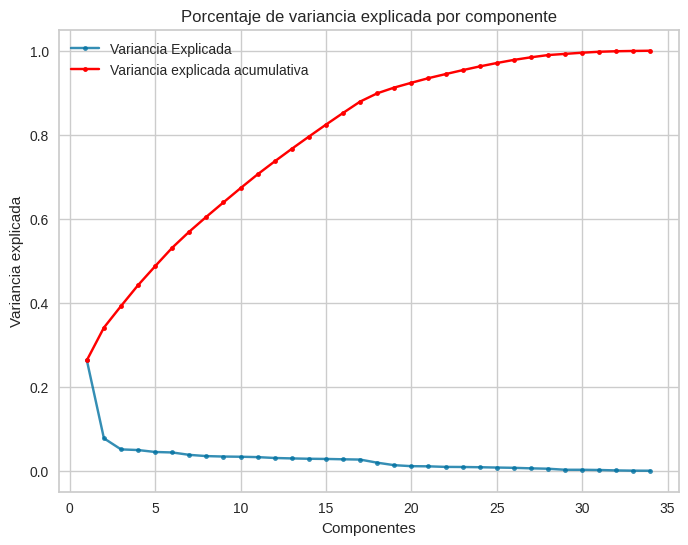

In [15]:
# Aplicar PCA a todos los datos estandarizados
pca_model = PCA().fit(X_train_scaled)
print("Varianza explicada:", pca_model.explained_variance_ratio_)
print("Varianza acumulada:", pca_model.explained_variance_ratio_.cumsum())

# Varianza explicada
fig = plt.figure(figsize=(8,6))
plt.plot(range(1, len(pca_model.explained_variance_ratio_) + 1), pca_model.explained_variance_ratio_, alpha=0.8, marker='.', label="Variancia Explicada")
plt.ylabel('Variancia explicada')
plt.xlabel('Componentes')
plt.plot(range(1, len(pca_model.explained_variance_ratio_) + 1),
         np.cumsum(pca_model.explained_variance_ratio_),
         c='red', marker='.',
         label="Variancia explicada acumulativa")
plt.legend()
plt.title('Porcentaje de variancia explicada por componente')

Como podemos observar, la información del conjunto de datos está muy distribuida y no depende de un solo factor. El primer componente (PC1) explica únicamente un 26% (0.26336386) de la varianza original, y la curva de varianza acumulada crece de forma gradual. El modelo necesita agrupar 15 componentes para llegar a retener un 80% (0.82411524) de la información original, lo que demuestra la complejidad del problema de la salud financiera.

Para entender cómo influyen las variables originales a la formación de los nuevos componentes, podemos hacer un heatmap para ver las relaciones (`annot = False` para que los números no se solapen y el heatmap sea legible). 

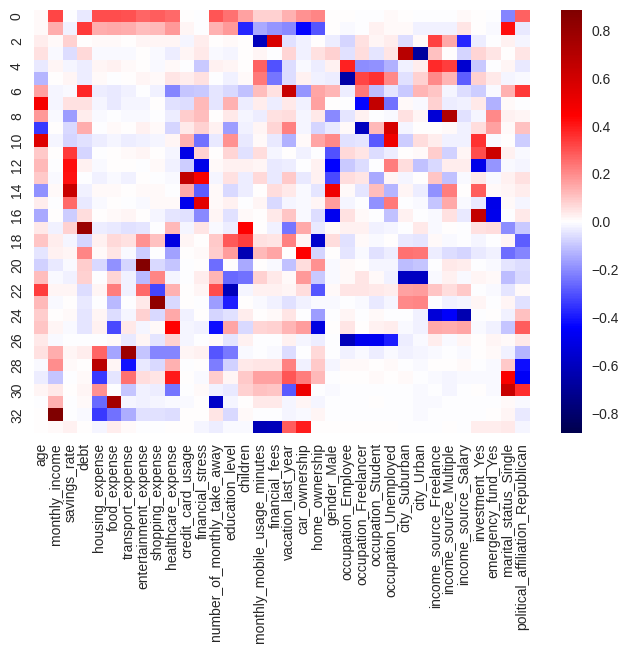

In [16]:
sns.heatmap(pca_model.components_, cmap='seismic', 
            xticklabels=list(X_train_scaled.columns),
            vmin=-np.max(np.abs(pca_model.components_)),
            vmax=np.max(np.abs(pca_model.components_)),
            annot=False);

Al tener que desactivar el atributo `annot` en el heatmap, no se pueden ver los pesos, pero a partir de los colores se pueden sacar las siguientes conclusiones: en la fila 0 (PC1), los pesos más altos y positivos (colores rojizos) se concentran en `monthly_income` y en otros gastos como `housing_expense` o `food_expense` (todas las variables acabadas en `_expense`). Esto indica que el PC1 agrupa principalmente a las personas según sus ingresos y gastos.

Para el resto de componentes, los pesos se distribuyen de forma muy distinta y variada entre el resto de variables, confirmando la complejidad vista antes en el Scree Plot.

A continuación, para ver la distribución de la variable objetivo, transformamos los datos usando el PCA entrenado, nos quedamos con los dos primeros componentes (PC1 y PC2) y los graficamos usando la variable objetivo como escala de color.

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA 2D - Distribución de Salud Financiera')

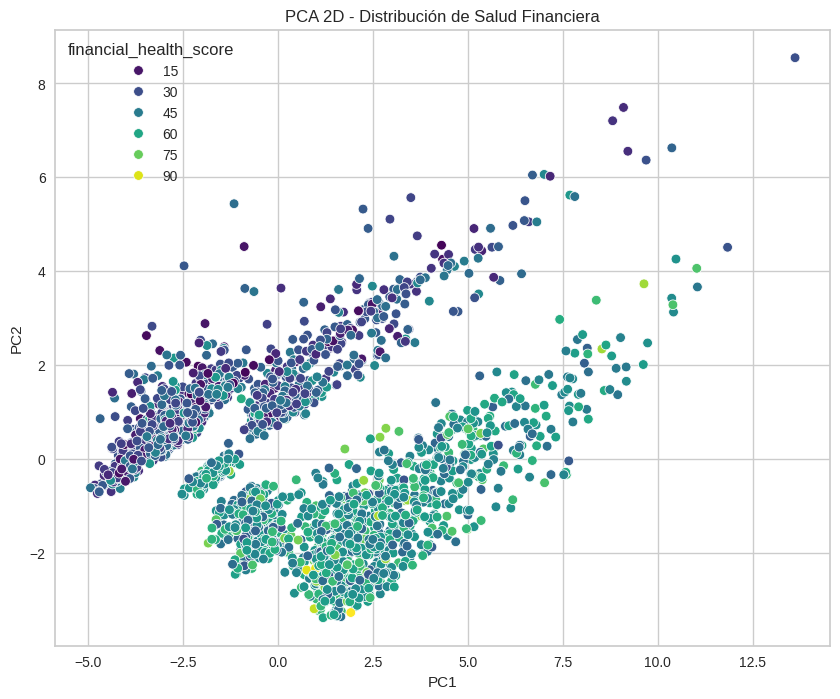

In [17]:
transformed_spending = pca_model.transform(X_train_scaled)

df_plot = X_train_scaled.copy()
df_plot['PC1'] = transformed_spending[:, 0]
df_plot['PC2'] = transformed_spending[:, 1]
df_plot['financial_health_score'] = y_train.values

fig = plt.figure(figsize=(10,8))
sns.scatterplot(x='PC1', y='PC2', hue='financial_health_score', data=df_plot, palette='viridis')
plt.title('PCA 2D - Distribución de Salud Financiera')

A partir de la gráfica anterior podemos ver que hay relación entre los componentes y la variable objetivo. Los puntos forman una estructura bifurcada (como de dos ramas) a medida que avanza por el eje PC1. Los valores más bajos de salud financiera (puntuaciones de 15 a 30) se concentran en el centro y en la rama superior, mientras que los valores de alta salud financiera (puntuaciones de 75 a 90) se agrupan en la parte inferior hacia la derecha. Esto demuestra que el PCA logra separar claramente a las personas con buena salud financiera de aquellas con problemas económicos.

Para entender qué separa las dos ramas del gráfico PCA, calcularemos la correlación de cada variable con la salud financiera (`financial_health_score`). Así identificaremos las características que más influyen (positiva y negativamente) y las usaremos para colorear el gráfico, comprobando si estas variables son las que realmente organizan los datos.

<Axes: title={'center': 'Correlación de cada variable con la variable objetivo'}>

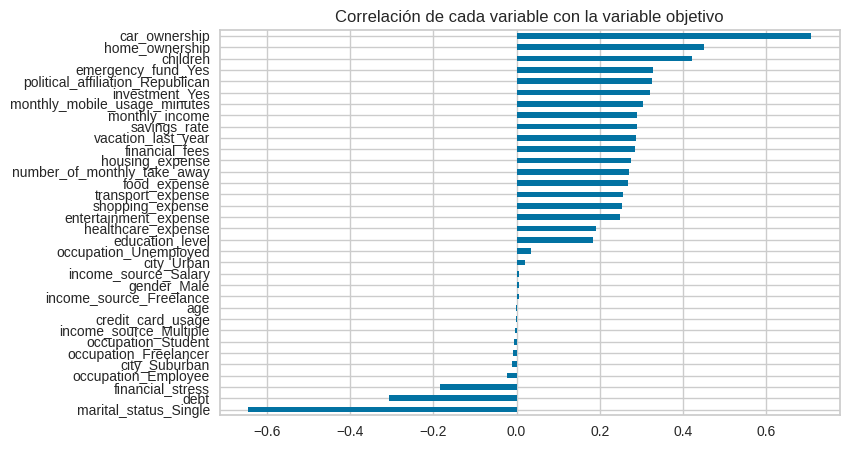

In [18]:
corr_target = X_train_scaled.corrwith(y_train.reset_index(drop=True)).sort_values()
corr_target.plot.barh(figsize=(8,5), title="Correlación de cada variable con la variable objetivo")
plt.show()

El gráfico muestra que tener coche (`car_ownership`), vivienda (`home_ownership`) e hijos (`children`) impactan muy positivamente en la salud financiera. Por el contrario, ser soltero (`marital_status_Single`), las deudas (`debt`) y no tener fondo de emergencia (`emergency_fund`) son los factores que más la empeoran.

A continuación, volveremos a dibujar el gráfico PCA en una cuadrícula de 6 gráficos, coloreando los puntos según estas variables clave para ver cómo estructuran el modelo internamente.

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA - Tenencia de Coche')

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA - Tenencia de Vivienda')

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA - Número de Hijos')

... (2 outputs left out)

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA - Estado Civil')

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA - Fondo de Emergencia')

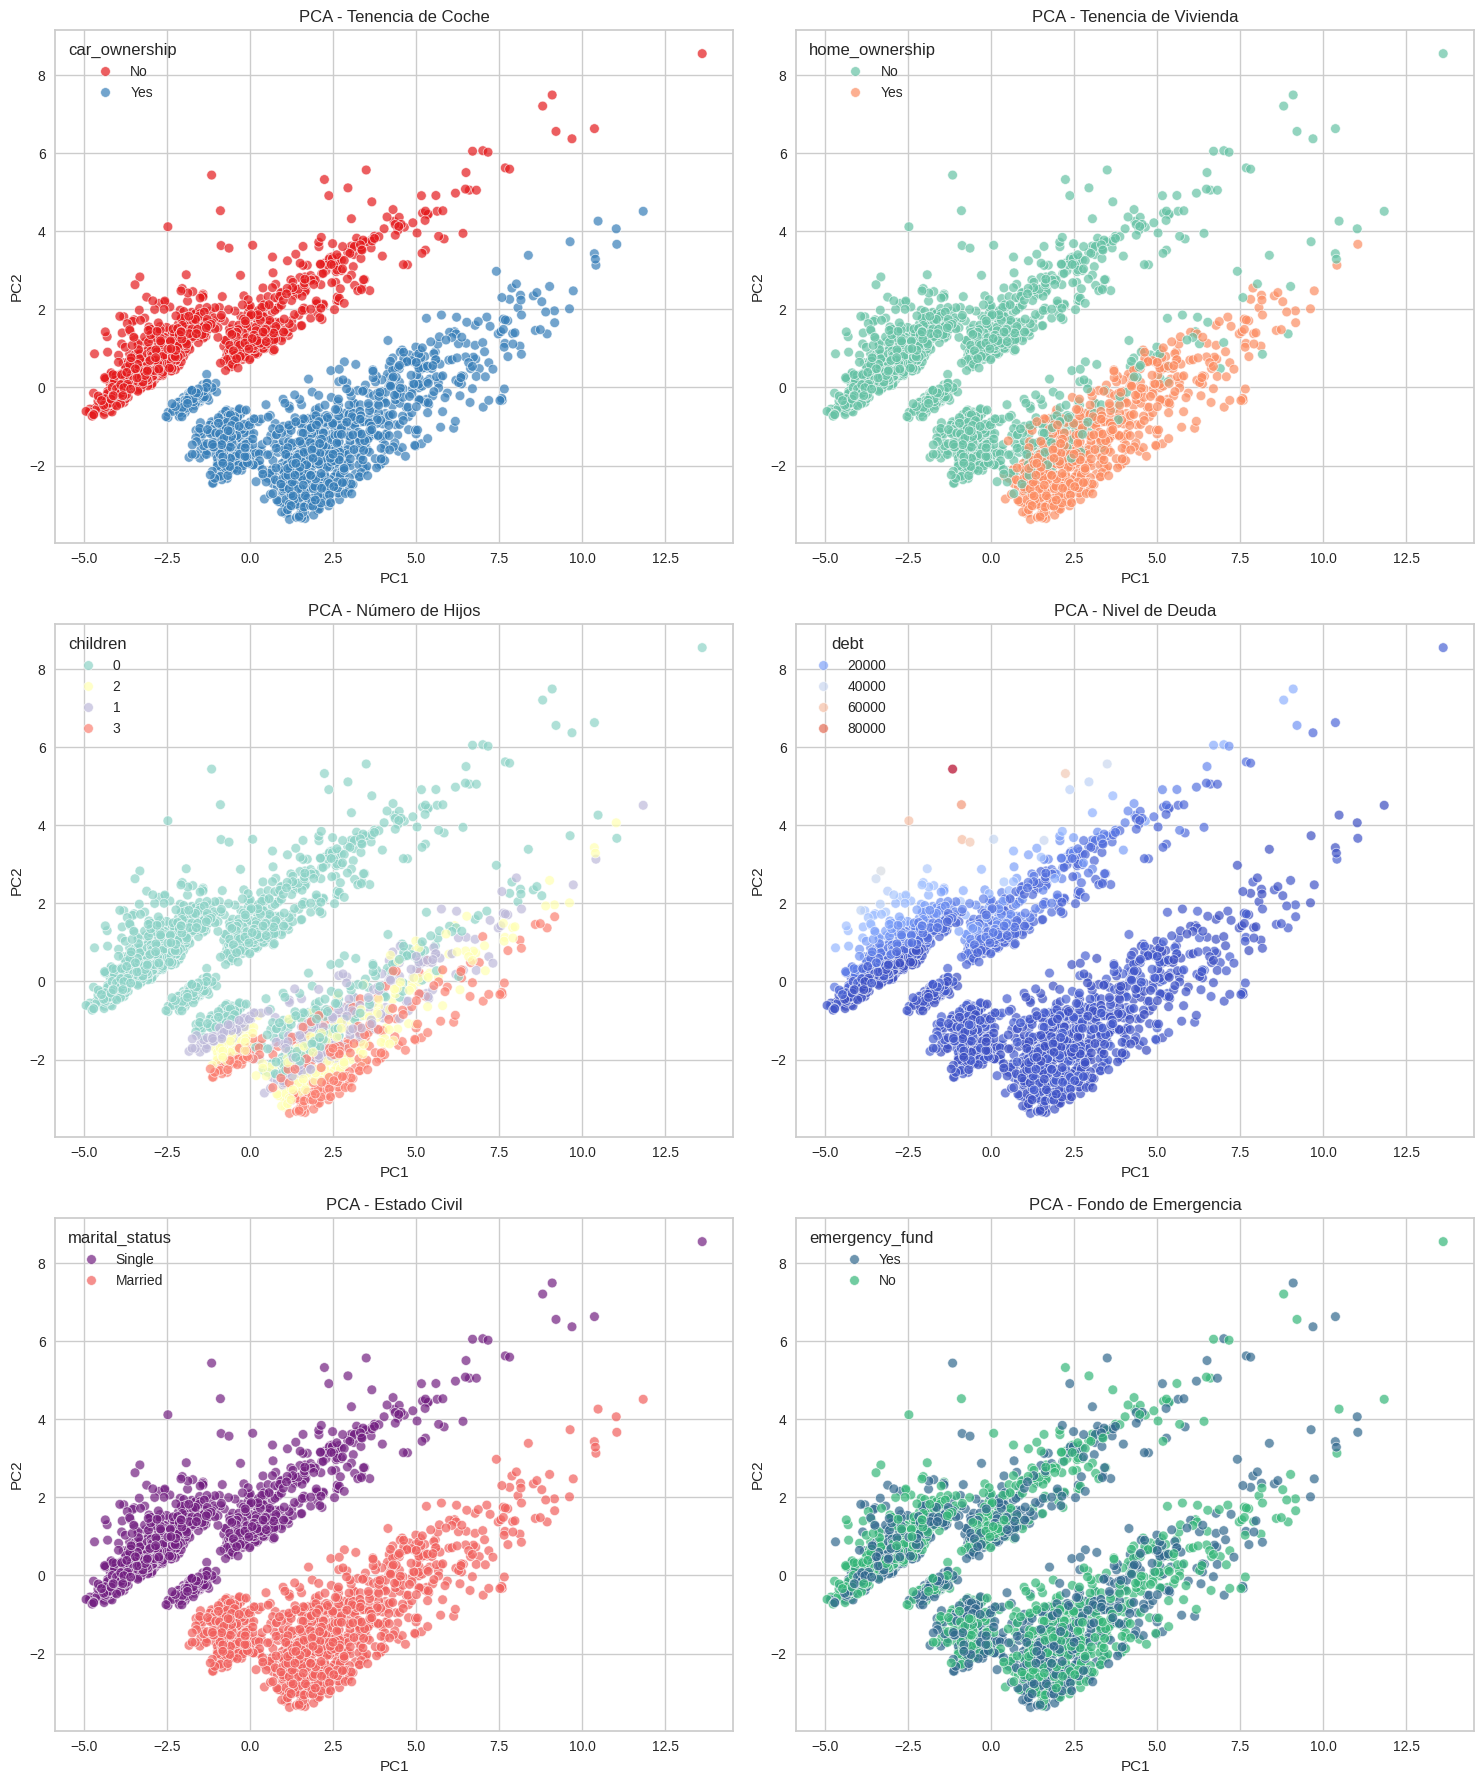

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Creamos DataFrame temporal con los componentes PCA
df_pca = pd.DataFrame({
    'PC1': transformed_spending[:, 0],
    'PC2': transformed_spending[:, 1]
})

# Añadimos las 6 variables desde el DataSet original (personalSpending)
df_pca['car_ownership'] = personalSpending.loc[y_train.index, 'car_ownership'].map({False: 'No', True: 'Yes'}).values
df_pca['home_ownership'] = personalSpending.loc[y_train.index, 'home_ownership'].map({False: 'No', True: 'Yes'}).values
df_pca['children'] = personalSpending.loc[y_train.index, 'children'].astype(str).values 
df_pca['debt'] = personalSpending.loc[y_train.index, 'debt'].values 
df_pca['marital_status'] = personalSpending.loc[y_train.index, 'marital_status'].values 
df_pca['emergency_fund'] = personalSpending.loc[y_train.index, 'emergency_fund'].values

# Creamos los graficos en una cuadricula
fig, axes = plt.subplots(3, 2, figsize=(15, 18))

sns.scatterplot(x='PC1', y='PC2', hue='car_ownership', data=df_pca, ax=axes[0, 0], palette='Set1', alpha=0.7)
axes[0, 0].set_title('PCA - Tenencia de Coche')

sns.scatterplot(x='PC1', y='PC2', hue='home_ownership', data=df_pca, ax=axes[0, 1], palette='Set2', alpha=0.7)
axes[0, 1].set_title('PCA - Tenencia de Vivienda')

sns.scatterplot(x='PC1', y='PC2', hue='children', data=df_pca, ax=axes[1, 0], palette='Set3', alpha=0.7)
axes[1, 0].set_title('PCA - Número de Hijos')

sns.scatterplot(x='PC1', y='PC2', hue='debt', data=df_pca, ax=axes[1, 1], palette='coolwarm', alpha=0.7)
axes[1, 1].set_title('PCA - Nivel de Deuda')

sns.scatterplot(x='PC1', y='PC2', hue='marital_status', data=df_pca, ax=axes[2, 0], palette='magma', alpha=0.7)
axes[2, 0].set_title('PCA - Estado Civil')

sns.scatterplot(x='PC1', y='PC2', hue='emergency_fund', data=df_pca, ax=axes[2, 1], palette='viridis', alpha=0.7)
axes[2, 1].set_title('PCA - Fondo de Emergencia')

plt.tight_layout()
plt.show()

Al observar estos gráficos, queda claro que el PCA ha agrupado a los usuarios basándose en su situación personal y económica:

- **Coche y Estado Civil:** Dividen el gráfico en dos de forma casi perfecta. Los solteros y quienes no tienen coche forman la rama superior, mientras que los casados y dueños de coche forman la rama inferior. Al estar los colores tan claramente separados, podemos decir que las personas con coche y las casadas tienen mejor salud financiera que las que no tienen coche o están solteras.

- **Vivienda:** Quienes tienen casa ("Sí") se agrupan en la esquina inferior derecha. Si miramos el gráfico original, esta es exactamente la zona con la mejor salud financiera (75 a 90 puntos).

- **Hijos:** El número de hijos crea franjas diagonales progresivas dentro de la rama inferior. Por tanto, se puede observar que en general cuántos más hijos se tienen, mejor es la salud financiera.

- **Deuda:** Las personas con mayores deudas (puntos rojos/naranjas) se concentran casi exclusivamente en la punta superior izquierda, marcando la zona de mayor riesgo financiero. Esto nos muestra que la salud financiera también influye en la deuda, y que aquellas personas que no tienen deudas (o que prácticamente no tienen) suelen ser las que tienen mejor salud financiera (cosa que tiene mucho sentido).

- **Fondo de Emergencia:** Aunque están más mezclados, quienes sí tienen un fondo se mueven hacia la derecha, alejándose de la zona de alta deuda.

En conclusión, el PCA ha conseguido encontrar patrones lógicos de forma automática, separando muy bien a las personas con buena salud financiera de aquellas en situación de riesgo, y nos ha ayudado a ver como se distribuyen las clases o valores de las variables en función de la salud financiera.

## APARTADO C

Para comenzar con este apartado, vamos a ajustar tres modelos diferentes a nuestros datos estandarizados y codificados: una Regresión Lineal clásica y dos regresiones regularizadas (Ridge y LASSO).

In [20]:
lambdas = [1e-4, 1e-3, 1e-2, 0.1, 0.5, 1, 5, 10, 50, 100]

lr = LinearRegression().fit(X_train_scaled, y_train)
lasso_cv = LassoCV(alphas=lambdas, cv=5, max_iter=50000).fit(X_train_scaled, y_train)
ridge_cv = RidgeCV(alphas=lambdas, cv=5).fit(X_train_scaled, y_train)

print('Mejor lambda LASSO:', lasso_cv.alpha_, '| Mejor lambda Ridge:', ridge_cv.alpha_)

Mejor lambda LASSO: 0.01 | Mejor lambda Ridge: 5.0


Una vez ajustados, podemos comprobar que el mejor valor de penalización para LASSO se encuentra en 0.01 y el de Ridge en 5.0.

Con estos parámetros fijados podemos proceder a evaluar los modelos para compararlos.

In [21]:
def tabla_resultados(modelos, X_train, y_train, X_test, y_test):
    res = pd.DataFrame(index=['Train R2', 'CV R2', 'Test R2', 'Test RMSE', 'Test MAE', 'lambda'])
    for nombre, m in modelos.items():
        pred_test = m.predict(X_test)
        res[nombre] = [
            r2_score(y_train, m.predict(X_train)),
            np.mean(cross_val_score(m, X_train, y_train, cv=5, scoring='r2')),
            r2_score(y_test, pred_test),
            np.sqrt(mean_squared_error(y_test, pred_test)),
            mean_absolute_error(y_test, pred_test),
            getattr(m, 'alpha_', 0),
        ]
    return res

modelos_c = {'LR': lr, 'ridge_cv': ridge_cv, 'lasso_cv': lasso_cv}
r2_results = tabla_resultados(modelos_c, X_train_scaled, y_train, X_test_scaled, y_test)
r2_results

,LR,ridge_cv,lasso_cv
Train R2,0.853,0.853,0.853
CV R2,0.848,0.848,0.848
Test R2,0.846,0.846,0.846
Test RMSE,6.001,6.005,5.994
Test MAE,4.818,4.827,4.815
lambda,0.000,5.000,0.010


Vemos que las tres regresiones tienen resultados muy parecidos, alcanzando un $R^2$ en la partición de test de 0.846. Esto nos indica que los modelos son capaces de explicar aproximadamente el 85% de la puntuación de salud financiera de una persona, lo cual es un resultado suficientemente bueno y robusto.

También podemos ver que la Regresión Lineal obtenida no sufre de sobreajuste masivo, por lo que su rendimiento es casi idéntico al de Ridge y LASSO.

Aunque los tres modelos en este caso son igual de válidos, elegiremos LASSO como el mejor modelo, ya que su penalización nos permite descartar variables y simplificar el problema.

### Comparación de pesos de los modelos
A continuación analizamos los pesos para ve si LASSO ha descartado variables.

Variables descartadas por LASSO: ['housing_expense', 'food_expense', 'political_affiliation_Republican']


<Axes: >

<Figure size 2000x100 with 0 Axes>

<Axes: >

<Figure size 2000x100 with 0 Axes>

<Axes: >

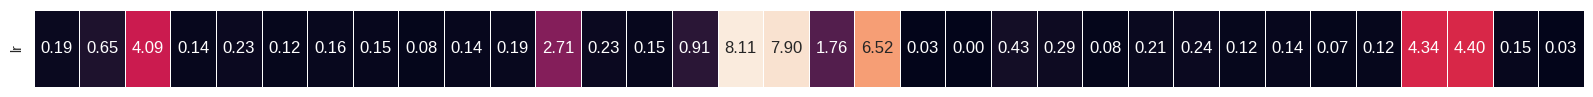

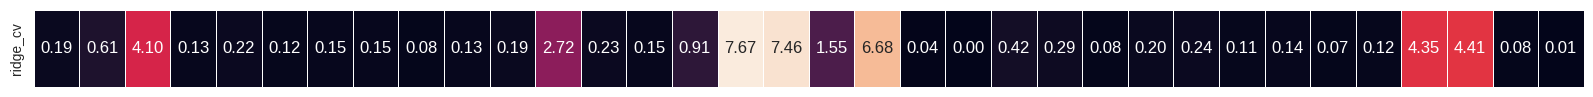

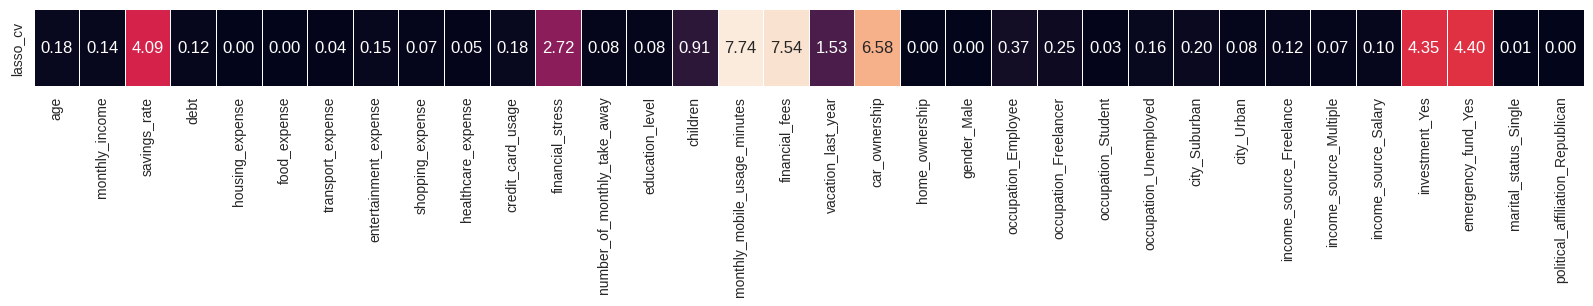

In [22]:
weights = pd.DataFrame({'lr': lr.coef_, 'ridge_cv': ridge_cv.coef_, 'lasso_cv': lasso_cv.coef_}, index=X_train_scaled.columns)

print('Variables descartadas por LASSO:', list(weights.index[weights['lasso_cv'] == 0]))

fig, ax = plt.subplots(figsize=(20,1))
sns.heatmap(weights.T.loc[['lr'],:].abs(), annot=True, fmt='.2f', linewidths=.5, ax=ax, cbar=False, xticklabels=False)

plt.figure(figsize=(20,1))
sns.heatmap(weights.T.loc[['ridge_cv'],:].abs(), annot=True, fmt='.2f', linewidths=.5, cbar=False, xticklabels=False)

plt.figure(figsize=(20,1))
sns.heatmap(weights.T.loc[['lasso_cv'],:].abs(), annot=True, fmt='.2f', linewidths=.5, cbar=False, xticklabels=True)
plt.show()

Al comparar los pesos de los tres modelos, observamos que las magnitudes generales se mantienen bastante estables entre LR y Ridge. También podemos ver que el modelo LASSO ha descartado 3 variables asignándoles un peso de cero (`housing_expense`, `food_expense` y `political_affiliation_Republican`).

Esto tiene sentido, ya que en la matriz de correlaciones inicial ya observamos que los gastos en vivienda y comida (en general variables acabadas en `_expense`) tenían una correlación muy alta con los ingresos mensuales (`monthly_income`). LASSO ha detectado esta redundancia y ha decidido quedarse con los ingresos como variable principal, eliminando variables que proporcionan información repetida. Por otro lado, ha detectado que la afiliación política republicana simplemente no aporta ningún valor predictivo real sobre la salud financiera.

### Representación de residuos y error de predicción del mejor modelo (LASSO)

Ahora podemos pasar a representar las predicciones y los residuos del modelo LASSO (o regresión lineal, al ser casi idénticos) para comprobar su fiabilidad.

<Figure size 1200x800 with 0 Axes>

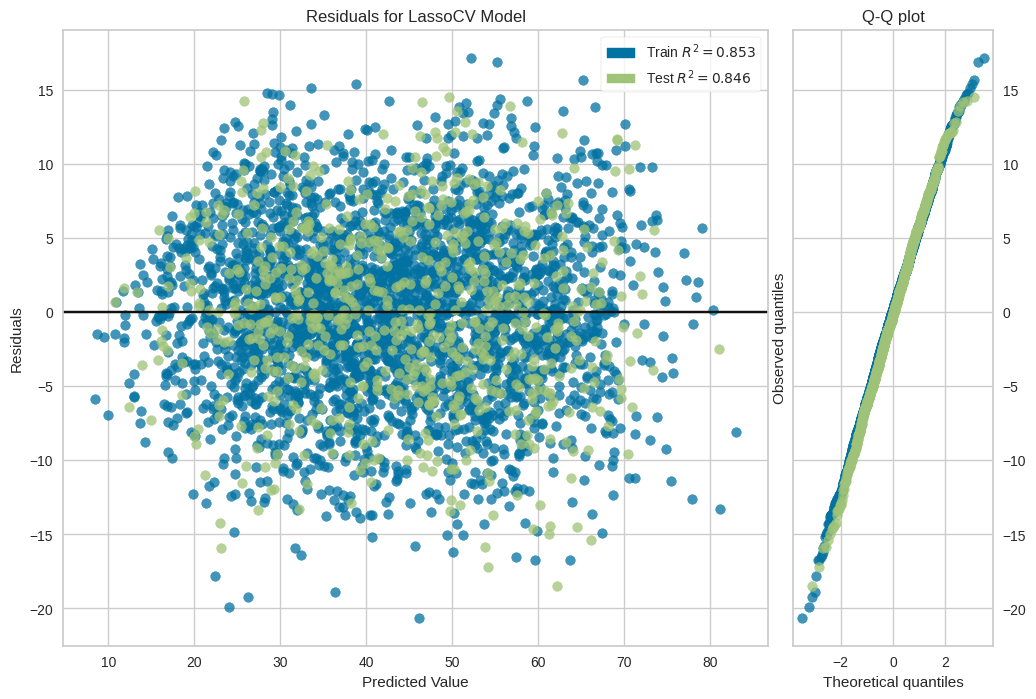

<Axes: title={'center': 'Residuals for LassoCV Model'}, xlabel='Predicted Value', ylabel='Residuals'>

In [23]:
plt.figure(figsize=(12,8))
viz = residuals_plot(lasso_cv, X_train_scaled, y_train, X_test_scaled, y_test, is_fitted=True, qqplot=True, hist=False)
viz.show()

En el Residuals Plot, los errores se distribuyen de forma bastante uniforme y horizontal alrededor de la línea del cero, sin formar un embudo evidente. Además, el Q-Q plot muestra que los cuantiles observados se alinean casi perfectamente con la distribución teórica gaussiana (solo hay una ligera curvatura en los extremos).

<Figure size 800x800 with 0 Axes>

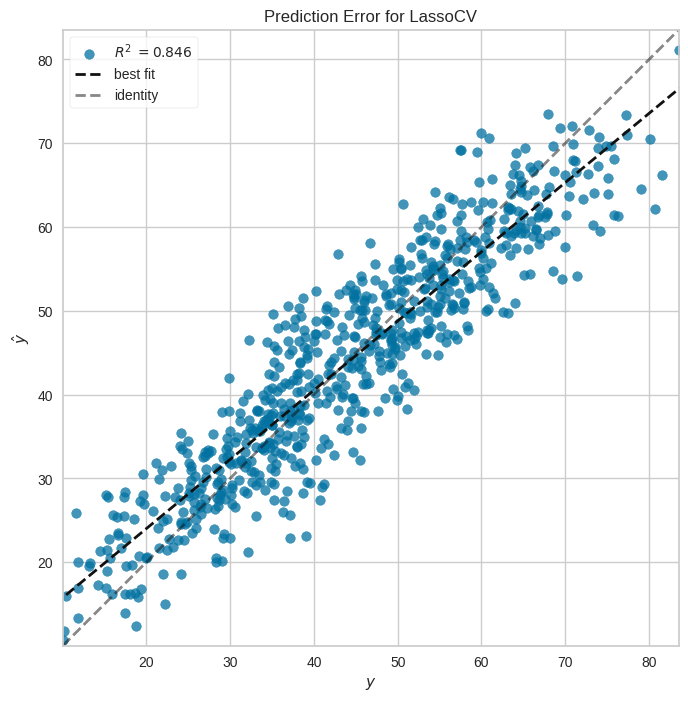

<Axes: title={'center': 'Prediction Error for LassoCV'}, xlabel='$y$', ylabel='$\\hat{y}$'>

In [24]:
plt.figure(figsize=(8,8))
visualizer = prediction_error(lasso_cv, X_test_scaled, y_test, is_fitted=True)
visualizer.show()

En la gráfica de Prediction Error, observamos que la nube de puntos se ajusta bastante bien a la línea identidad, lo que confirma el buen $R^2$ de 0.846. El modelo es capaz de predecir de forma sólida en casi todo el rango de valores.

En base a estos resultados, podemos concluir con que sí que parece totalmente adecuado usar regresión lineal con estos datos, ya que se cumplen las asunciones matemáticas y se demuestra una fuerte relación lineal entre los marcadores sociodemográficos/financieros y el `financial_health_score`.

### Reajuste de la Regresión Lineal con las variables seleccionadas por LASSO
Por último, comprobamos si obtenemos el mismo modelo usando solo las variables que tienen peso diferente de cero en la regresión LASSO.

In [25]:
# Filtramos las variables con peso diferente de cero en LASSO
variables_activas = weights.index[weights['lasso_cv'] != 0]

X_train_filtrado = X_train_scaled[variables_activas]
X_test_filtrado = X_test_scaled[variables_activas]

# Ajustamos una nueva Regresión Lineal con estas variables
lr_filtrado = LinearRegression().fit(X_train_filtrado, y_train)

# Comparamos resultados usando la función creada anteriormente
modelos_filtrados = {'LR_Filtrada': lr_filtrado}
r2_results_filtrado = tabla_resultados(modelos_filtrados, X_train_filtrado, y_train, X_test_filtrado, y_test)
r2_results_filtrado

,LR_Filtrada
Train R2,0.853
CV R2,0.848
Test R2,0.846
Test RMSE,6.001
Test MAE,4.816
lambda,0.000


Al ajustar de nuevo la Regresión Lineal, se obtiene el mismo modelo ($R^2$ en Test de 0.846). Esto demuestra que las tres variables descartadas eran redundantes y podíamos prescindir de ellas sin penalizar la precisión de nuestras predicciones.

En conclusión, se obtiene el mismo modelo pero más eficiente.

## APARTADO D

Algunos fenómenos económicos se pueden explicar mucho mejor a partir de las interacciones entre las variables. Por ello, utilizaremos a continuación la función `PolynomialFeatures` para añadir al conjunto de datos original nuevas características que correspondan a polinomios de grado 2. 

Al utilizar el parámetro `interaction_only=True`, nos aseguramos de que el algoritmo se limite a multiplicar las variables entre sí de dos en dos, descartando los cuadrados de una misma variable.

In [26]:
# Aplicar PolynomialFeatures de grado 2
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)

# Ajustamos y transformamos usando los datos escalados del apartado anterior
X_train_poly_arr = poly.fit_transform(X_train_scaled)
X_test_poly_arr = poly.transform(X_test_scaled)

poly_features_names = poly.get_feature_names_out(X_train_scaled.columns)
X_train_poly = pd.DataFrame(X_train_poly_arr, columns=poly_features_names)
X_test_poly = pd.DataFrame(X_test_poly_arr, columns=poly_features_names)

print(f"Número de características originales: {X_train_scaled.shape[1]}")
print(f"Número de características tras aplicar interacciones: {X_train_poly.shape[1]}")

Número de características originales: 34
Número de características tras aplicar interacciones: 595


Al aplicar PolynomialFeatures con `interaction_only=True`, el espacio de características ha pasado de tener 34 variables originales a tener un total de 595, multiplicando todas las variables entre sí de dos en dos. Esto nos permitirá comprobar si existen sinergias complejas en el comportamiento financiero que en el modelo lineal simple no se podían ver.

Para comprobarlo, entrenamos nuevamente Ridge y LASSO con esta nueva cantidad de datos.

In [27]:
ridge_poly = RidgeCV(alphas=lambdas, cv=5).fit(X_train_poly, y_train)

# max_iter aumenta para darle tiempo al algoritmo a converger
lasso_poly = LassoCV(alphas=lambdas, cv=5, max_iter=100000).fit(X_train_poly, y_train)

print('Mejor lambda LASSO Poly:', lasso_poly.alpha_, '| Mejor lambda Ridge Poly:', ridge_poly.alpha_)

Mejor lambda LASSO Poly: 0.01 | Mejor lambda Ridge Poly: 0.1


Con el nuevo espacio de alta dimensionalidad (595 variables), los modelos han encontrado nuevos hiperparámetros óptimos: $\lambda = 0.01$ para LASSO y $\lambda = 0.1$ para Ridge.

Ahora podemos proceder a evaluar los modelos para comprobar si estas interacciones sirven de algo.

In [28]:
modelos_poly = {'Ridge_Poly': ridge_poly, 'Lasso_Poly': lasso_poly}
r2_results_poly = tabla_resultados(modelos_poly, X_train_poly, y_train, X_test_poly, y_test)
display(r2_results_poly)

,Ridge_Poly,Lasso_Poly
Train R2,0.961,0.957
CV R2,0.936,0.943
Test R2,0.936,0.941
Test RMSE,3.862,3.716
Test MAE,2.960,2.831
lambda,0.100,0.010


Con esta tabla, podemos ver con claridad que los modelos han mejorado significativamente.

Al incorporar las interacciones, el $R^2$ del conjunto de Test ha subido de un $0.846$ (apartado C) a un $0.936$ para Ridge y un $0.941$ para LASSO. Esto demuestra que en la salud financiera de las personas, las variables no actúan de forma aislada, y que el efecto de una variable cambia drásticamente cuando se combina con otra.

Además, vemos que en este entorno de tantas variables, LASSO se comporta un poco mejor que Ridge tanto en Validación Cruzada ($0.943$ vs $0.936$) como en Test ($0.941$ vs $0.936$), confirmando que filtrar ruido es útil cuando la complejidad de los datos es tan alta.

Antes de pasar a la recta final y analizar qué pesos ha escogido cada modelo, podemos volver a generar las gráficas de residuos (Residuals) y de error de predicción (Prediction Error) para visualizar claramente cómo han mejorado los modelos gracias a las interacciones de grado 2.

Text(0.5, 1.0, 'Ridge CV (Poly) - Residuals')

Text(0.5, 1.0, 'Ridge CV (Poly) - Prediction Error')

Text(0.5, 1.0, 'Lasso CV (Poly) - Residuals')

Text(0.5, 1.0, 'Lasso CV (Poly) - Prediction Error')

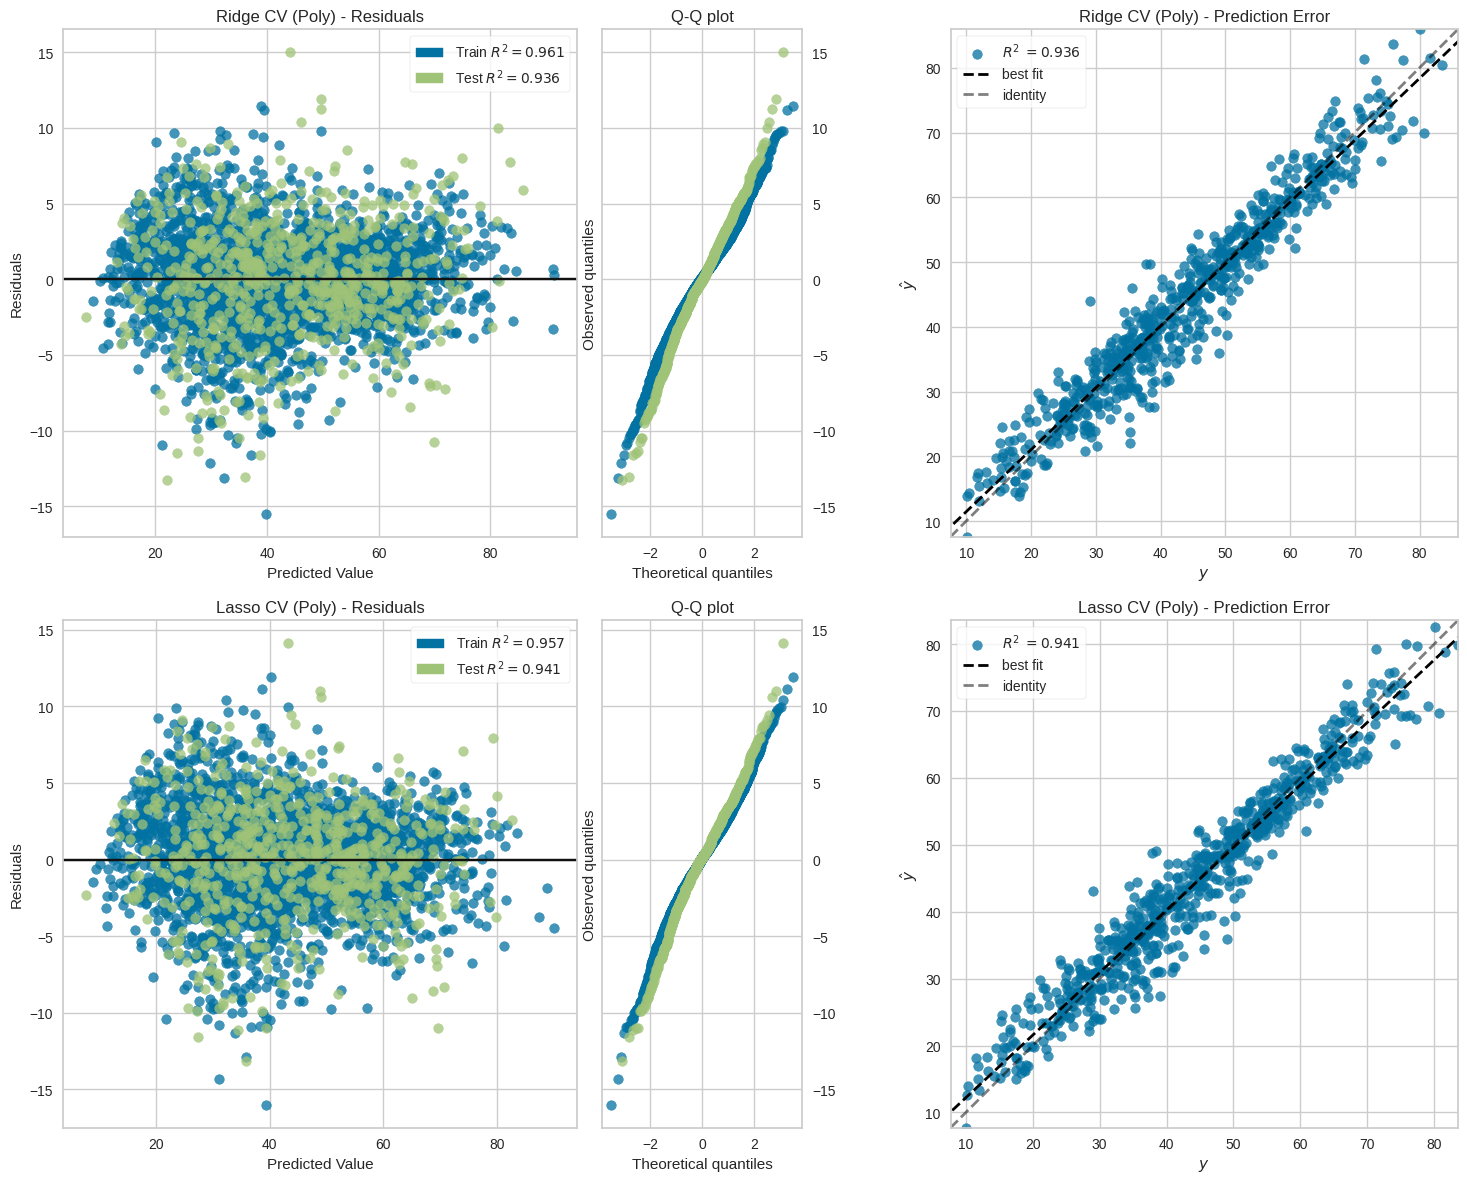

In [31]:
# LR + Ridge
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
modelos_poly_graficas = [("Ridge CV (Poly)", ridge_poly), ("Lasso CV (Poly)", lasso_poly)]

for i, (nombre, modelo) in enumerate(modelos_poly_graficas):
    
    # Gráfico de residuos (asignamos a "_" para bloquear el error de Jupyter)
    _ = residuals_plot(modelo, X_train_poly, y_train, X_test_poly, y_test,
                       is_fitted=True, qqplot=True, hist=False, ax=axes[i, 0], show=False)
    axes[i, 0].set_title(f"{nombre} - Residuals")
    
    # Gráfico de error de predicción (añadimos line_color='black' por seguridad)
    _ = prediction_error(modelo, X_test_poly, y_test, 
                         is_fitted=True, ax=axes[i, 1], show=False, line_color='black')
    axes[i, 1].set_title(f"{nombre} - Prediction Error")

plt.tight_layout()
plt.show()

Al observar estos nuevos gráficos, la mejora visual respecto al modelo lineal del apartado C es indiscutible.

Si nos fijamos en las gráficas del Prediction Error, vemos cómo la nube de puntos se ha estrechado mucho si la comparamos con la del apartado C. Ahora, los puntos siguen la línea de identidad punteada casi a la perfección. Esto nos confirma el enorme salto del $R^2$, que como ya hemos dicho antes, ha pasado de un 0.84 a un excelente 0.936 en Ridge y 0.941 en LASSO para el conjunto de Test.

En cuánto a las gráficas de Residuals, la dispersión de los errores está mucho más concentrada en torno a la línea del cero (la mayoría de los puntos se encuentran en el rango estrecho de -5 a 5, mientras que antes llegaban hasta el rango [-20, 15]). Además, los Q-Q plots también se han mantenido e incluso mejorado, siguiendo de forma casi perfecta la diagonal teórica, confirmando que los residuos se comportan como una distribución normal de manera aún más estricta que en el modelo sin interacciones.

Para acabar, podemos hacer unas últimas comprobaciones para hacer un análisis de pesos y simplicidad de ambos modelos (Ridge y LASSO) y hacer una comprobación del top 10 interacciones con mayor peso entre ambos.

In [30]:
# Análisis de pesos y simplicidad
weights_poly = pd.DataFrame({
    'Ridge': ridge_poly.coef_,
    'LASSO': lasso_poly.coef_
}, index=poly_features_names)

# Simplicidad de LASSO
ceros_lasso_poly = (weights_poly['LASSO'] == 0).sum()
total_vars = len(poly_features_names)
print(f"Variables anuladas por LASSO: {ceros_lasso_poly}/{total_vars} ({(ceros_lasso_poly/total_vars)*100:.1f}%).\n")

#  Top 10 de interacciones con mayor peso
top_ridge = weights_poly['Ridge'].abs().sort_values(ascending=False).head(10).index
top_lasso = weights_poly['LASSO'].abs().sort_values(ascending=False).head(10).index

print("--- TOP 10 Variables/Interacciones con más peso en RIDGE ---")
print(weights_poly.loc[top_ridge, 'Ridge'])

print("\n--- TOP 10 Variables/Interacciones con más peso en LASSO ---")
print(weights_poly.loc[top_lasso, 'LASSO'])

Variables anuladas por LASSO: 227/595 (38.2%).

--- TOP 10 Variables/Interacciones con más peso en RIDGE ---
monthly_mobile_usage_minutes financial_fees           -39.165
monthly_mobile_usage_minutes                           35.028
financial_fees                                         34.025
monthly_mobile_usage_minutes car_ownership             19.015
financial_fees car_ownership                           18.970
vacation_last_year                                    -17.482
monthly_mobile_usage_minutes vacation_last_year        13.825
financial_fees vacation_last_year                      13.547
vacation_last_year political_affiliation_Republican   -13.113
car_ownership                                         -12.947
Name: Ridge, dtype: float64

--- TOP 10 Variables/Interacciones con más peso en LASSO ---
monthly_mobile_usage_minutes financial_fees       -34.307
monthly_mobile_usage_minutes                       30.881
financial_fees                                     29.994
vacatio

Frente a un problema con 595 características, LASSO ha logrado descartar 227 variables (el 38.2% del modelo) que ha considerado redundantes, simplificando el modelo considerablemente.

Al observar el Top 10 de variables/interacciones con mayor peso, podemos observar que las interacciones de mayor peso coinciden casi a la perfección en ambos modelos.

La interacción con un impacto más determinante en ambos modelos es `monthly_mobile_usage_minutes * financial_fees`. También destacan fuertemente sus efectos por separado, así como las interacciones conjuntas con tener coche (`car_ownership`) o haber tenido vacaciones (`vacation_last_year`).

La única diferencia notable en el Top 10 es una elección de correlación: mientras que Ridge le da mucho peso a la interacción `vacation_last_year * political_affiliation_Republican`, LASSO prefiere reducir o descartar esa y otorgarle el peso a `vacation_last_year * marital_status_Single`. Esto es un comportamiento clásico de LASSO -> al haber varias interacciones fuertemente correlacionadas que explican lo mismo, escoge una como "representante" y descarta o reduce las demás.